# Normalización de los cutouts `.fits` para la red

Fase 2 (MaNGA + Legacy Survey). `notebook/exploration_fits.ipynb` mostró cómo llega un `.fits`:
nanomaggies por píxel nativo, cielo casi restado, sin `NaN` y volteado respecto al `.jpg`. Este
notebook decide **cómo convertirlo en un tensor que una CNN pueda consumir** sin perder la
información morfológica y sin introducir atajos.

Pasos que se evalúan, en orden:

1. **Restar el cielo** de cada banda.
2. **Estirar** el rango dinámico (lineal, log, asinh por banda, asinh tipo Lupton).
3. **Elegir la suavidad** del asinh (β).
4. **Escalar**: constantes globales (todo el dataset) o por imagen.
5. **Recortar, estandarizar por canal** y revisar el almacenamiento (`float16`).

La lógica adoptada vive en `src/data/fits_normalization.py` y sus parámetros en `src/config.py`
(`FITS_NORM_*`); ver `README.md`, sección "Normalización de los .fits". Muestra: las 50 galaxias
(25/25) con `.fits` en la variante activa.

In [1]:
# importaciones de sistema
import sys
from pathlib import Path

# Referencia a otros archivos sin necesidad de instalar el paquete
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# importaciones de librerias de terceros
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

In [2]:
# configuracion de proyecto
from src.config import (
    CUTOUT_FORMAT_FITS,
    CUTOUTS_INDEX_CSV,
    EARLY_TYPE_LABEL,
    FITS_NORM_CLIP_MAX,
    FITS_NORM_CLIP_MIN,
    FITS_NORM_SCHEME_GLOBAL,
    FITS_NORM_SCHEME_PER_IMAGE,
    FITS_NORM_SOFTENING_SIGMA,
    LATE_TYPE_LABEL,
    LEGACY_BANDS,
    LEGACY_LAYER,
    LEGACY_REGION_NORTH,
    LEGACY_REGION_SOUTH,
    MORFOLOGIA_LABEL_TO_INT,
    RANDOM_SEED,
)
from src.data.cutout_io import (
    fits_pixscale,
    fits_to_image_orientation,
    load_fits_cutout,
    load_jpg_cutout,
)
from src.data.fits_normalization import (
    channel_stats,
    fit_global_reference,
    intensity_noise,
    lupton_asinh,
    normalize_fits_cube,
    reference_flux,
    standardize,
    subtract_sky,
)
from src.data.fits_photometry import build_fits_photometry_table, radius_grid
from src.data.image_quality import legacy_region
from src.data.legacy_cutouts import list_cutout_names
from src.data.morfologia import load_morfologia
from src.utils import set_seed

set_seed(RANDOM_SEED)
LAYER, BANDS = LEGACY_LAYER, LEGACY_BANDS

# Colores fijos por entidad (los mismos que notebook/exploration_fits.ipynb).
LABEL_COLORS = {EARLY_TYPE_LABEL: "#eb6834", LATE_TYPE_LABEL: "#2a78d6"}
REGION_COLORS = {LEGACY_REGION_NORTH: "#1baf7a", LEGACY_REGION_SOUTH: "#4a3aa7"}
BAND_COLORS = {"g": "#2a78d6", "r": "#1baf7a", "z": "#e34948"}
SCHEME_COLORS = {FITS_NORM_SCHEME_GLOBAL: "#2a78d6", FITS_NORM_SCHEME_PER_IMAGE: "#eb6834"}
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e5e4e0",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984",
    "figure.dpi": 100,
})

## 1. Datos

Se cargan los 50 cubos crudos una sola vez, con su `pixscale` (del WCS) y `PETRO_TH90`. La
fotometría de `src/data/fits_photometry.py` (colores g − r) sirve de referencia para comprobar que
la normalización no destruye el color.

In [3]:
names = list_cutout_names(CUTOUT_FORMAT_FITS, LAYER, BANDS)
index = pd.read_csv(CUTOUTS_INDEX_CSV)
index = index[(index["format"] == CUTOUT_FORMAT_FITS) & (index["layer"] == LAYER)
              & (index["bands"] == BANDS) & index["name"].isin(names)]
galaxies = (
    index[["name", "label", "objra", "objdec", "PETRO_TH90"]]
    .merge(load_morfologia()[["name", "Type", "nsa_z", "LogMass"]], on="name", how="left")
    .sort_values("name", ignore_index=True)
)
galaxies["region"] = legacy_region(galaxies["objra"], galaxies["objdec"])
photometry = build_fits_photometry_table(galaxies, LAYER, BANDS).set_index("name")

raw = {n: load_fits_cutout(n, LAYER, BANDS) for n in galaxies["name"]}
pixscale = {n: fits_pixscale(n, LAYER, BANDS) for n in galaxies["name"]}
petro = galaxies.set_index("name")["PETRO_TH90"].to_dict()
y = galaxies["label"].map(MORFOLOGIA_LABEL_TO_INT).to_numpy()

late = galaxies[galaxies["label"] == LATE_TYPE_LABEL].sort_values("PETRO_TH90", ignore_index=True)
EXAMPLE = late.loc[len(late) // 2, "name"]  # la misma galaxia de ejemplo que exploration_fits
pick = pd.concat([
    galaxies[galaxies["label"] == label].sample(3, random_state=RANDOM_SEED)
    for label in (EARLY_TYPE_LABEL, LATE_TYPE_LABEL)
])
print(len(galaxies), "galaxias; ejemplo:", EXAMPLE)

50 galaxias; ejemplo: manga-11945-12705


## 2. El problema: el rango crudo

Si se muestran todas las galaxias con una sola escala lineal (la que haría un `min/max` global), el
resultado depende por completo del brillo de cada una:

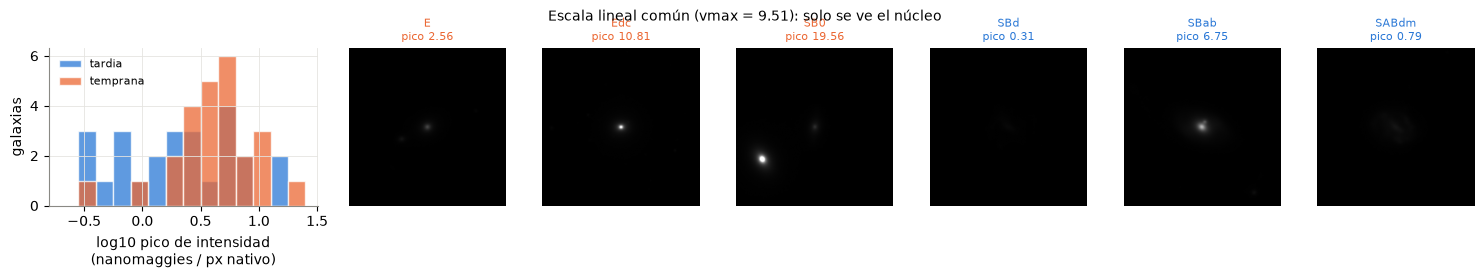

el pico varía 67× entre galaxias; mediana tempranas 4.17, tardías 2.20


In [4]:
peaks = pd.Series({n: raw[n].mean(axis=0).max() for n in raw})
vmax = np.percentile(peaks, 90)
fig, axes = plt.subplots(1, len(pick) + 1, figsize=(15, 2.8), gridspec_kw={"width_ratios": [1.6] + [1] * len(pick)})
for label, group in galaxies.assign(pico=galaxies["name"].map(peaks)).groupby("label"):
    axes[0].hist(np.log10(group["pico"]), bins=np.linspace(-0.7, 1.4, 15), alpha=0.75,
                 color=LABEL_COLORS[label], edgecolor="white", linewidth=1, label=label)
axes[0].set_xlabel("log10 pico de intensidad\n(nanomaggies / px nativo)")
axes[0].set_ylabel("galaxias")
axes[0].legend(frameon=False, fontsize=8)
for ax, galaxy in zip(axes[1:], pick.itertuples()):
    ax.imshow(fits_to_image_orientation(raw[galaxy.name].mean(axis=0)), cmap="gray", vmin=0, vmax=vmax)
    ax.set_title(f"{galaxy.Type}\npico {peaks[galaxy.name]:.2f}", fontsize=8, color=LABEL_COLORS[galaxy.label])
    ax.axis("off")
fig.suptitle(f"Escala lineal común (vmax = {vmax:.2f}): solo se ve el núcleo", fontsize=10)
plt.tight_layout()
plt.show()
print(f"el pico varía {peaks.max() / peaks.min():.0f}× entre galaxias; mediana tempranas "
      f"{peaks[galaxies.loc[galaxies.label == EARLY_TYPE_LABEL, 'name']].median():.2f}, "
      f"tardías {peaks[galaxies.loc[galaxies.label == LATE_TYPE_LABEL, 'name']].median():.2f}")

Dos problemas a la vez:

- **Rango dinámico dentro de cada imagen:** el núcleo es ~100× más brillante que el disco, donde
  están los brazos. En escala lineal el disco queda en negro.
- **Rango entre galaxias:** el pico varía ~70×, y las tempranas lo tienen ~2× más alto. Cómo se
  maneje esa diferencia decide qué información de brillo le llega a la red (sección 6).

## 3. Paso 1: restar el cielo

El pipeline del survey ya resta casi todo el cielo, pero queda un residuo positivo. Se mide con
recorte sigma fuera de 1.5 × `PETRO_TH90` (`subtract_sky`).

In [5]:
rows = []
for galaxy in galaxies.itertuples():
    clean, noise = subtract_sky(raw[galaxy.name], pixscale[galaxy.name], petro[galaxy.name])
    sky = raw[galaxy.name].reshape(3, -1).mean(axis=1) - clean.reshape(3, -1).mean(axis=1)
    rows.append({"region": galaxy.region, **{f"cielo_{b}": s for b, s in zip(BANDS, sky)},
                 **{f"cielo/ruido_{b}": s / n for b, s, n in zip(BANDS, sky, noise)}})
sky_table = pd.DataFrame(rows).groupby("region").median().T
sky_table.round(4)

region,norte,sur
cielo_g,0.0006,0.0005
cielo_r,0.0016,0.0013
cielo_z,0.0004,0.0027
cielo/ruido_g,0.3550,0.2598
cielo/ruido_r,0.4367,0.3428
cielo/ruido_z,0.0392,0.2209


El residuo es una fracción del ruido (0.2–0.4σ en g y r, en las dos regiones), pero en **z cambia
con la región**: 0.04σ en el norte y 0.22σ en el sur. Sin restarlo, las imágenes del sur tendrían un
fondo z más alto: otra pista de región para la red. Se resta siempre.

## 4. Paso 2: cómo estirar el rango dinámico

Cuatro opciones sobre la galaxia de ejemplo (renders RGB con R ← z, G ← r, B ← g):

- **lineal:** recortada al percentil 99.5.
- **log:** `log10(1 + x/ε)`, que amplifica el ruido del cielo.
- **asinh por banda:** cada banda con su propio estiramiento. Comprime el núcleo, pero cambia los
  cocientes entre bandas.
- **asinh tipo Lupton** (`lupton_asinh`): el mismo factor `asinh(I/β)/(I/β)` multiplica las tres
  bandas de cada píxel, con `I` la intensidad media. El color se conserva.

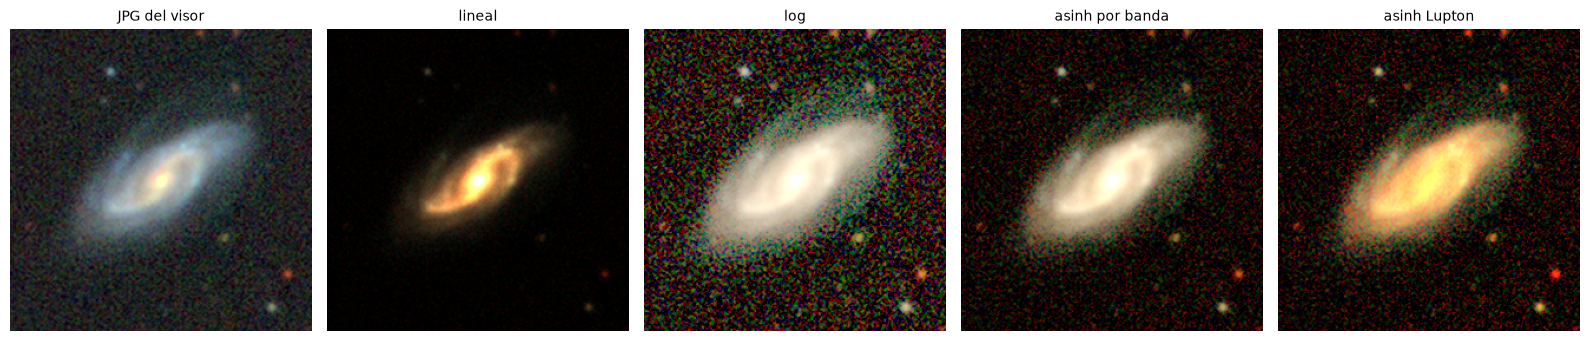

In [6]:
def per_band_asinh(clean, softening):
    # asinh independiente por banda (no conserva el color); solo para comparar
    return np.arcsinh(clean / softening)


def to_rgb(cube, top):
    # R <- z, G <- r, B <- g, escalado a [0, 1]
    return np.clip(np.stack([cube[2], cube[1], cube[0]], axis=-1) / top, 0, 1)


clean, _ = subtract_sky(raw[EXAMPLE], pixscale[EXAMPLE], petro[EXAMPLE])
clean = fits_to_image_orientation(clean)
beta = FITS_NORM_SOFTENING_SIGMA * intensity_noise(clean, pixscale[EXAMPLE], petro[EXAMPLE])
stretches = {
    "lineal": clean,
    "log": np.log10(1 + np.clip(clean, 0, None) / (0.1 * beta)),
    "asinh por banda": per_band_asinh(clean, beta),
    "asinh Lupton": lupton_asinh(clean, beta),
}
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
axes[0].imshow(load_jpg_cutout(EXAMPLE, LAYER, BANDS))
axes[0].set_title("JPG del visor", fontsize=10)
for ax, (title, cube) in zip(axes[1:], stretches.items()):
    ax.imshow(to_rgb(cube, np.percentile(cube.mean(axis=0), 99.5)))
    ax.set_title(title, fontsize=10)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

La lineal pierde el disco y la log hace visible el ruido del cielo. Las dos asinh muestran el disco
y los brazos sin saturar el núcleo, pero la **asinh por banda** lleva el color hacia el gris: cada
banda se comprime por separado y la banda más brillante (z) se comprime más.

(El tono anaranjado de los renders propios es solo de visualización: las galaxias son más brillantes
en z, que va al canal rojo, y aquí no se reequilibran los canales como hace el visor. A la red le
llegan las tres bandas como canales separados.)

¿Cuánto color conserva cada una? Se compara, en las 50 galaxias, el g − r medido en el `.fits`
(fotometría de apertura) con el g − r de la mediana píxel a píxel dentro de `PETRO_TH90` en el cubo
estirado:

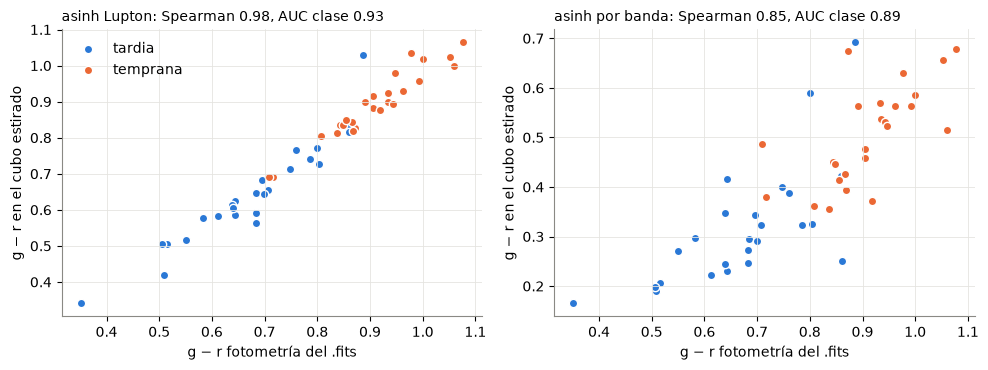

In [7]:
def stretched_color(cube, radius, petro_th90):
    inside = (radius <= petro_th90) & (cube[0] > 0) & (cube[1] > 0)
    return -2.5 * np.log10(np.median(cube[0][inside] / cube[1][inside]))

rows = []
for galaxy in galaxies.itertuples():
    clean, _ = subtract_sky(raw[galaxy.name], pixscale[galaxy.name], petro[galaxy.name])
    radius = radius_grid(clean.shape[1:], pixscale[galaxy.name])
    beta = FITS_NORM_SOFTENING_SIGMA * intensity_noise(clean, pixscale[galaxy.name], petro[galaxy.name])
    rows.append({
        "g_r_fotometria": photometry.loc[galaxy.name, "g_r"],
        "asinh Lupton": stretched_color(lupton_asinh(clean, beta), radius, galaxy.PETRO_TH90),
        "asinh por banda": stretched_color(per_band_asinh(clean, beta), radius, galaxy.PETRO_TH90),
        "label": galaxy.label,
    })
colors = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
for ax, method in zip(axes, ["asinh Lupton", "asinh por banda"]):
    for label, group in colors.groupby("label"):
        ax.scatter(group["g_r_fotometria"], group[method], s=36, color=LABEL_COLORS[label],
                   edgecolor="white", linewidth=1, label=label)
    rho = spearmanr(colors["g_r_fotometria"], colors[method]).statistic
    auc = roc_auc_score(y, -colors[method])
    ax.set_title(f"{method}: Spearman {rho:.2f}, AUC clase {auc:.2f}", fontsize=10, loc="left")
    ax.set_xlabel("g − r fotometría del .fits")
    ax.set_ylabel("g − r en el cubo estirado")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

Con Lupton el color del cubo estirado sigue casi exactamente al g − r físico (Spearman 0.98) y
conserva su poder para separar las clases (AUC 0.93). Por banda, el rango de colores se comprime
(de 0.35–1.05 a 0.17–0.70), la relación con el color físico se debilita (Spearman 0.85) y la
separación baja (0.89). **Se adopta asinh tipo Lupton.**

## 5. Paso 3: la suavidad β

`β = FITS_NORM_SOFTENING_SIGMA × σ` (σ = ruido del cielo de la intensidad). Por debajo de β la
respuesta es lineal y por encima logarítmica. Un β chico estira mucho el cielo, que se vuelve
granulado. Un β grande se acerca a la lineal y esconde el disco débil.

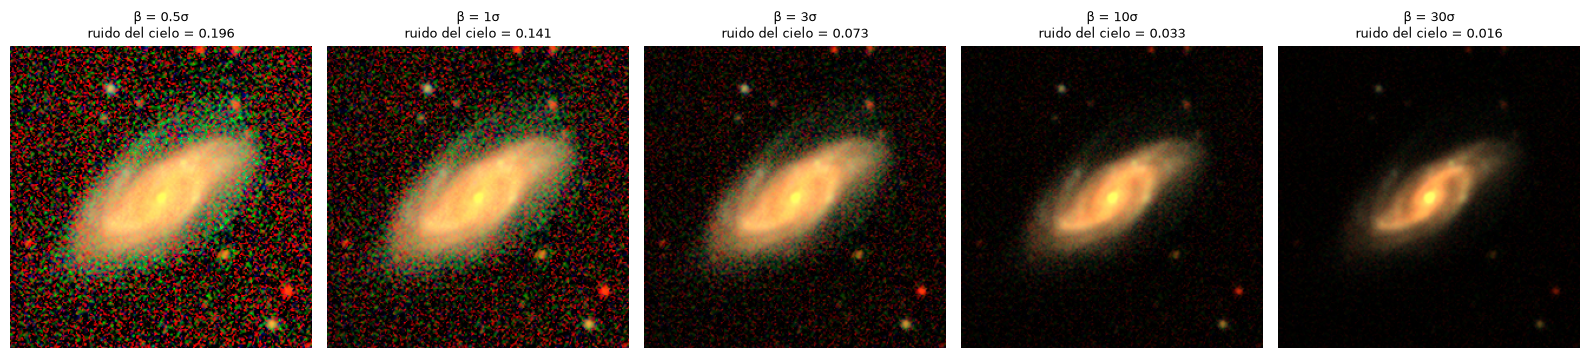

In [8]:
clean, _ = subtract_sky(raw[EXAMPLE], pixscale[EXAMPLE], petro[EXAMPLE])
clean = fits_to_image_orientation(clean)
sigma = intensity_noise(clean, pixscale[EXAMPLE], petro[EXAMPLE])
ref = reference_flux(clean, pixscale[EXAMPLE], petro[EXAMPLE])
radius = radius_grid(clean.shape[1:], pixscale[EXAMPLE])
sky_pixels = radius > 1.5 * petro[EXAMPLE]

ks = [0.5, 1, 3, 10, 30]
fig, axes = plt.subplots(1, len(ks), figsize=(16, 3.6))
for ax, k in zip(axes, ks):
    stretched = lupton_asinh(clean, k * sigma) / np.arcsinh(ref / (k * sigma))
    ax.imshow(to_rgb(stretched, 1.0))
    sky_std = stretched.mean(axis=0)[sky_pixels].std()
    ax.set_title(f"β = {k}σ\nruido del cielo = {sky_std:.3f}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

Con β = 3σ (el valor de `FITS_NORM_SOFTENING_SIGMA`) el cielo queda en ~0.06 de la escala, el
disco es visible y el núcleo no satura. Con β ≤ 1σ el cielo ocupa una fracción grande de la escala
(la red vería mucha textura de ruido); con β ≥ 10σ el disco externo se apaga. Es un parámetro
razonable, no óptimo: vale la pena barrerlo después con el modelo entrenado.

## 6. Paso 4: escala global o por imagen

Falta decidir qué flujo vale 1:

- **Global** (`FITS_NORM_SCHEME_GLOBAL`): β y el flujo de referencia son constantes del dataset
  (`fit_global_reference`: mediana del ruido y percentil 90 de los núcleos). Una galaxia más
  brillante se ve más brillante. Las constantes se miden **solo con el set de entrenamiento**.
- **Por imagen** (`FITS_NORM_SCHEME_PER_IMAGE`): β y la referencia salen de cada galaxia (su
  ruido y el percentil 99.5 de su intensidad dentro de `PETRO_TH90`). Todas llegan con el núcleo
  en ~1.

Aquí las constantes globales se miden con las 50 (no hay split todavía):

GlobalNormReference(noise=0.003920132602006174, ref_flux=3.1105467017293003)


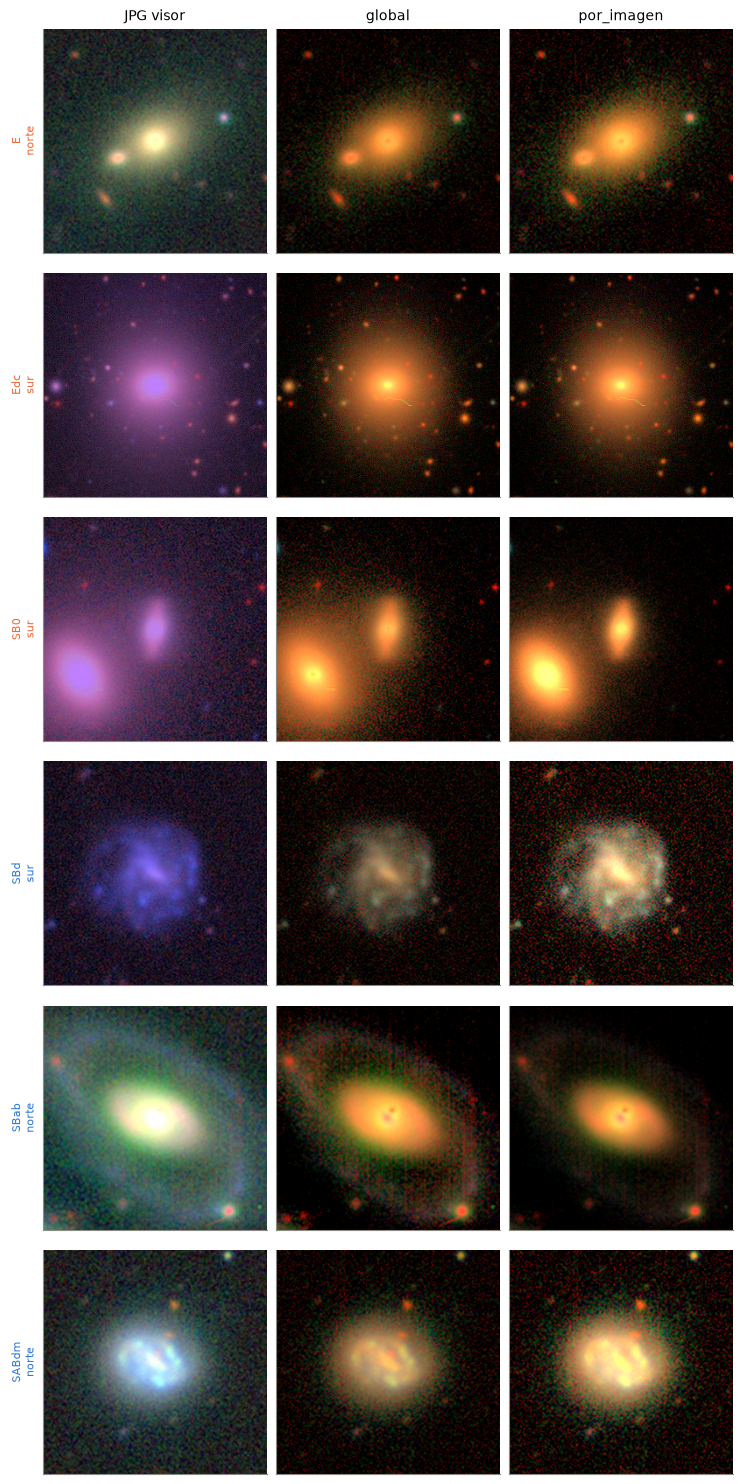

In [9]:
reference = fit_global_reference((raw[n], pixscale[n], petro[n]) for n in galaxies["name"])
print(reference)

normalized = {
    scheme: {n: normalize_fits_cube(raw[n], pixscale[n], petro[n], scheme, reference) for n in galaxies["name"]}
    for scheme in (FITS_NORM_SCHEME_GLOBAL, FITS_NORM_SCHEME_PER_IMAGE)
}

columns = ["JPG visor", FITS_NORM_SCHEME_GLOBAL, FITS_NORM_SCHEME_PER_IMAGE]
fig, axes = plt.subplots(len(pick), 3, figsize=(7.5, 2.5 * len(pick)))
for row, galaxy in enumerate(pick.itertuples()):
    images = [load_jpg_cutout(galaxy.name, LAYER, BANDS)] + [
        to_rgb(normalized[scheme][galaxy.name], 1.0) for scheme in columns[1:]
    ]
    for col, image in enumerate(images):
        axes[row, col].imshow(image)
        axes[row, col].set_xticks([]); axes[row, col].set_yticks([]); axes[row, col].grid(False)
        if row == 0:
            axes[row, col].set_title(columns[col], fontsize=10)
    axes[row, 0].set_ylabel(f"{galaxy.Type}\n{galaxy.region}", fontsize=8, color=LABEL_COLORS[galaxy.label])
plt.tight_layout()
plt.show()

Visualmente los dos muestran la misma estructura. La diferencia está en **qué información extra,
además de la forma, lleva cada uno**. Se resume cada imagen normalizada en tres números que una red
puede "leer" sin mirar la morfología, y se mide cuánto predicen la clase (AUC) y cuánto siguen al
redshift (Spearman):

- **núcleo:** percentil 99.5 de la intensidad dentro de `PETRO_TH90` (brillo central);
- **galaxia mediana:** mediana de la intensidad dentro de `PETRO_TH90` (cuánto disco hay respecto
  al núcleo, relacionado con la concentración);
- **ruido del cielo:** desviación de la intensidad fuera de 1.5 × `PETRO_TH90` (relación
  señal/ruido de la imagen).

In [10]:
def image_summary(cube, pixscale_value, petro_th90):
    intensity = cube.mean(axis=0)
    radius = radius_grid(intensity.shape, pixscale_value)
    inside = radius <= petro_th90
    return {
        "núcleo": np.percentile(intensity[inside], 99.5),
        "galaxia mediana": np.median(intensity[inside]),
        "ruido del cielo": intensity[radius > 1.5 * petro_th90].std(),
    }

rows = []
for scheme, cubes in normalized.items():
    summary = pd.DataFrame([image_summary(cubes[n], pixscale[n], petro[n]) for n in galaxies["name"]])
    for feature in summary.columns:
        auc = roc_auc_score(y, summary[feature])
        rows.append({
            "esquema": scheme, "resumen": feature,
            "AUC clase": max(auc, 1 - auc),
            "Spearman con redshift": spearmanr(summary[feature], galaxies["nsa_z"]).statistic,
            "Spearman con masa": spearmanr(summary[feature], galaxies["LogMass"]).statistic,
        })
leak = pd.DataFrame(rows).set_index(["resumen", "esquema"]).sort_index()
leak.round(3)

AUC clase  Spearman con redshift  \
resumen         esquema                                        
galaxia mediana global          0.501                 -0.002   
                por_imagen      0.626                 -0.161   
núcleo          global          0.746                  0.304   
                por_imagen      0.538                  0.092   
ruido del cielo global          0.525                  0.062   
                por_imagen      0.667                 -0.250   

                            Spearman con masa  
resumen         esquema                        
galaxia mediana global                  0.091  
                por_imagen             -0.151  
núcleo          global                  0.452  
                por_imagen              0.026  
ruido del cielo global                  0.112  
                por_imagen             -0.324

Cómo leer la tabla (n = 50, intervalos anchos):

- **Global** conserva el **brillo del núcleo**, que separa las clases porque las tempranas tienen
  centros más brillantes. Es una propiedad física de la galaxia (la misma que mide la
  concentración C), pero también sigue a la masa y, a través de la selección de MaNGA, al redshift.
  El ruido del cielo no informa: todas las imágenes comparten la misma escala de ruido.
- **Por imagen** borra el brillo absoluto (el núcleo vale ~1 en todas). La "galaxia mediana" pasa
  a separar algo (relación disco/núcleo, que sí es morfología), pero **la información de brillo se
  muda al ruido**: en una galaxia tenue el cielo ocupa una fracción mayor de la escala, así que el
  nivel de ruido de la imagen pasa a separar las clases. Es peor: el ruido es una propiedad de la
  observación, no de la galaxia.

**Se adopta el esquema global** (`FITS_NORM_SCHEME`). Como conserva el brillo, al evaluar el modelo
hay que comprobar que no dependa de él: AUC con pesos a masa y redshift iguales
(`matching_weights` en `src/data/shortcuts.py`) y, como aumento de datos, escalar el flujo de cada
imagen por un factor aleatorio antes de normalizar.

## 7. Paso 5: recorte, estandarización y almacenamiento

Distribución de los valores normalizados (esquema global), por canal, juntando las 50 imágenes:

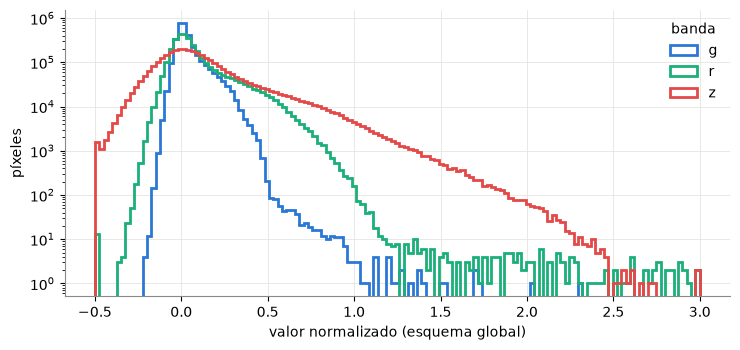

,por debajo del mínimo,por encima del máximo
g,0.000000,3.051758e-07
r,0.000004,6.103516e-07
z,0.000308,6.103516e-07


In [11]:
cubes = normalized[FITS_NORM_SCHEME_GLOBAL]
stack = np.stack(list(cubes.values()))  # (n, 3, H, W)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
bins = np.linspace(FITS_NORM_CLIP_MIN, FITS_NORM_CLIP_MAX, 140)
for i, band in enumerate(BANDS):
    ax.hist(stack[:, i].ravel(), bins=bins, histtype="step", linewidth=2, color=BAND_COLORS[band], label=band)
ax.set_yscale("log")
ax.set_xlabel("valor normalizado (esquema global)")
ax.set_ylabel("píxeles")
ax.legend(title="banda", frameon=False)
plt.tight_layout()
plt.show()

clipped = pd.DataFrame({
    "por debajo del mínimo": [(stack[:, i] <= FITS_NORM_CLIP_MIN).mean() for i in range(3)],
    "por encima del máximo": [(stack[:, i] >= FITS_NORM_CLIP_MAX).mean() for i in range(3)],
}, index=list(BANDS))
clipped

- El pico alrededor de 0 es el cielo; la cola hasta ~1–2 es la galaxia. **z llega más lejos que g**
  porque las galaxias son más brillantes en z (el color se conserva).
- El recorte en `[FITS_NORM_CLIP_MIN, FITS_NORM_CLIP_MAX]` afecta a una fracción mínima de píxeles
  (núcleos muy rojos y estrellas saturadas). Con un máximo de 1.5 se cortaban núcleos en z, por eso
  quedó en 3.0.

**Estandarización por canal.** La red recibe cada canal con media 0 y desviación 1, usando
estadísticas del set de entrenamiento (`channel_stats`, `standardize`):

In [12]:
mean, std = channel_stats(cubes.values())
standardized = standardize(cubes[EXAMPLE], mean, std)
print("media por canal:", mean.round(4), " desviación:", std.round(4))
print("ejemplo estandarizado: media", standardized.reshape(3, -1).mean(axis=1).round(3),
      "desv", standardized.reshape(3, -1).std(axis=1).round(3))

as_f16 = np.stack([c.astype(np.float16) for c in cubes.values()])
error = np.abs(as_f16.astype(np.float32) - stack)
sky_noise = np.median([cubes[n].mean(axis=0)[radius_grid((256, 256), pixscale[n]) > 1.5 * petro[n]].std() for n in cubes])
print(f"float16: error máx {error.max():.5f}, ruido típico del cielo {sky_noise:.3f} -> error {error.max() / sky_noise:.1%} del ruido")
print(f"peso por cubo: float32 {stack[0].nbytes / 1024:.0f} KB, float16 {as_f16[0].nbytes / 1024:.0f} KB")

media por canal: [0.0386 0.0782 0.1133]  desviación: [0.0782 0.1547 0.2695]
ejemplo estandarizado: media [ 0.011 -0.065 -0.099] desv [1.077 0.955 0.872]
float16: error máx 0.00097, ruido típico del cielo 0.064 -> error 1.5% del ruido
peso por cubo: float32 768 KB, float16 384 KB


Guardar los cubos ya normalizados en `float16` **no pierde nada útil**: el error de redondeo
máximo es ~1.5% del ruido del cielo (y está en los píxeles más brillantes, donde la precisión
relativa de `float16` sigue siendo de ~0.05%). A 384 KB por cubo, el dataset completo (~10 mil galaxias) ocupa
~3.8 GB en lugar de ~7.6 GB, y se evita normalizar en cada época.

## 8. ¿Y la diferencia norte/sur?

La normalización no está pensada para quitar la diferencia de filtros entre regiones (ver
`notebook/exploration_fits.ipynb`, sección 9), pero conviene saber cuánto queda. Se compara la
fracción de la intensidad que aporta cada banda dentro de `PETRO_TH90`, por región y clase:

In [13]:
rows = []
for galaxy in galaxies.itertuples():
    cube = cubes[galaxy.name]
    inside = (radius_grid((256, 256), pixscale[galaxy.name]) <= galaxy.PETRO_TH90) & (cube.sum(axis=0) > 0)
    totals = np.array([cube[i][inside].sum() for i in range(3)])
    rows.append({"region": galaxy.region, "label": galaxy.label,
                 **{f"fraccion_{b}": t / totals.sum() for b, t in zip(BANDS, totals)}})
fractions = pd.DataFrame(rows).groupby(["label", "region"]).median()
fractions.round(3)

fraccion_g  fraccion_r  fraccion_z
label    region                                    
tardia   norte        0.184       0.340       0.490
         sur          0.183       0.326       0.490
temprana norte        0.153       0.359       0.493
         sur          0.141       0.309       0.552

En las **tempranas** el sur aporta más fracción en z (0.55 contra 0.49) y menos en r: es la
diferencia de filtros (r − z mayor en DECam) que se vio en la fotometría. En las tardías la
diferencia casi desaparece en esta muestra. La normalización conserva esa diferencia tal cual,
porque conserva el color. Las opciones para quitarla, si el modelo resulta sensible a la región, son:

- aplicar las transformaciones de color entre DECam y BASS/MzLS que publica Legacy Surveys antes
  de normalizar;
- estandarizar cada canal con estadísticas por región;
- entrenar con aumento de color pequeño por canal.

Primero conviene medir si hace falta, con el AUC por región del modelo entrenado.

## 9. Conclusiones y pipeline adoptado

Pipeline en `src/data/fits_normalization.py` (`normalize_fits_cube`):

1. **Restar el cielo** de cada banda (`subtract_sky`): imprescindible en z del sur.
2. **asinh tipo Lupton** (`lupton_asinh`) con **β = 3σ** del ruido de la intensidad: comprime el
   núcleo, deja visible el disco y **conserva el color** (el asinh por banda lo destruye).
3. **Escala global** (`fit_global_reference`, solo con el set de entrenamiento): el percentil 90 de
   los núcleos vale 1. Se prefiere a la escala por imagen porque esta convierte el brillo en
   **ruido aparente**, que es un atributo de la observación.
4. **Recorte** a `[-0.5, 3.0]` y orientación de `.jpg`.
5. **Estandarización por canal** con estadísticas del entrenamiento (`channel_stats`,
   `standardize`). Guardar los cubos normalizados en `float16` (error ≤ 1.5% del ruido).

Uso:

```python
reference = fit_global_reference((cube, pixscale, petro_th90) for ... in train)
x = normalize_fits_cube(cube, pixscale, petro_th90, reference=reference)   # (3, 256, 256) float32
mean, std = channel_stats(normalize_fits_cube(...) for ... in train)
x = standardize(x, mean, std)
```

**Pendiente (no resuelto aquí):**

- **Extinción galáctica:** corregir cada banda con E(B − V) por coordenadas antes de normalizar
  (necesita un mapa de polvo, p. ej. SFD, o la columna `ebv` del catálogo de Legacy Surveys).
- **Nitidez (PSF)** distinta por imagen: homogeneizar o usarla como aumento de datos.
- **Diferencia de filtros norte/sur:** decidir si se corrige, después de medir el AUC por región.
- **Sensibilidad al brillo:** evaluar el modelo con pesos a masa y redshift iguales, y probar
  aumento de datos que escale el flujo.
- Barrer β (`FITS_NORM_SOFTENING_SIGMA`) con el modelo entrenado.